# Example spectrograms (Fig. 1 C-D, Fig. 2 B and D)

Draws the example songs of a starling and a zebra finch in regular air and in heliox (Fig. 1 C-D), and the example syllables of each species in the two conditions (Fig. 2 B and D).

Reads one file, `spectrogram_examples_data.pkl`, written by Cells X1 to X3 of the data notebook. The spectrograms are computed there, from the recordings; this notebook only draws them, so it needs no audio and no audio packages.

The phrase names, the Break and Restart arrows and the song diagrams of Fig. 1 C-D were added in the layout program and are not drawn here.

In [1]:
# Cell 1: paths and figure style
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
FIG_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'spectrogram_examples_data.pkl')
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'font.size': 15, 'axes.titlesize': 19, 'axes.labelsize': 16, 'xtick.labelsize': 14,
                     'ytick.labelsize': 14, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
CONDITIONS = [('regair', 'Regular Air'), ('heliox', 'Heliox')]


def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(FIG_DIR, f'{name}.{ext}'))
    print('saved', os.path.join(FIG_DIR, name + '.png'))

In [2]:
# Cell 2: load
data = pd.read_pickle(DATA_PATH)
panels = data['panels'].set_index('panel_id')
images, song_syllables = data['images'], data['song_syllables']
print('made', data['meta']['created'])
print(panels.groupby('figure').size().rename('panels').to_string())

made 2026-10-11T12:18:03
figure
1C    2
1D    2
2B    4
2D    6


In [3]:
# Cell 3: drawing helpers
# Letters under the zebra finch song (I = introductory note, A-F = motif syllables) and their colours.
LETTER_COLORS = {'I': '#ff7f0e', 'A': '#8e44ad', 'B': '#4daf4a', 'C': '#a65628', 'D': '#f781bf', 'E': '#e41a1c', 'F': '#1414b8'}


def show(ax, panel_id):
    """One stored spectrogram: white is the floor of its dB range, black the ceiling."""
    p = panels.loc[panel_id]
    ax.imshow(images[panel_id], origin='lower', aspect='auto', cmap='gray_r', vmin=0, vmax=255,
              extent=[p['t0'], p['t1'], p['f0_khz'], p['f1_khz']])
    return p


def syllable_bars(ax, panel_id, xlim):
    """One bar per syllable under a song. Zebra finch bars are coloured by syllable type, with the
    letter of the type beneath; starling bars are grey."""
    syl = song_syllables[song_syllables['panel_id'] == panel_id]
    types = sorted(syl['label'].unique())
    fallback = {lab: plt.get_cmap('tab10')(i % 10) for i, lab in enumerate(types)}
    zebra_finch = panels.loc[panel_id, 'species'] == 'zebra_finch'
    for onset, offset, label, letter in zip(syl['onset_s'], syl['offset_s'], syl['label'], syl['letter']):
        color = LETTER_COLORS.get(letter, fallback[label]) if zebra_finch else '#9e9e9e'
        ax.add_patch(Rectangle((onset, 0), offset - onset, 1, facecolor=color, edgecolor='black', linewidth=0.6))
        if zebra_finch:
            ax.text((onset + offset) / 2, -0.25, letter if letter else str(label), color=color, ha='center', va='top', fontsize=14)
    ax.set_xlim(xlim)
    ax.set_ylim(-1.2, 1)
    ax.axis('off')


def draw_songs(figure, name, figsize):
    """Fig. 1 C or D: for each condition, the song and the bars of its syllables."""
    have = [(cond, title) for cond, title in CONDITIONS if f'{figure}_1_{cond}' in panels.index]
    if not have:
        print(f'Fig. {figure}: no songs in the data file yet (see the [TO DO] lines of Cell X3)')
        return
    fig = plt.figure(figsize=(figsize[0], figsize[1] * len(have) / 2))
    # per condition: the song, room for its time axis, the syllable bars, a gap before the next song
    grid = GridSpec(4 * len(have), 1, figure=fig, height_ratios=[4, 1.1, 0.8, 0.6] * len(have), hspace=0)
    for row, (cond, title) in enumerate(have):
        ax = fig.add_subplot(grid[4 * row])
        p = show(ax, f'{figure}_1_{cond}')
        ax.set_title(title, loc='left', fontweight='bold')
        ax.set_ylabel('Frequency (kHz)')
        ax.set_xlabel('Time (s)', fontsize=14, labelpad=1)
        syllable_bars(fig.add_subplot(grid[4 * row + 2]), f'{figure}_1_{cond}', (p['t0'], p['t1']))
    save(fig, name)
    plt.show()


LABEL_EVERY_COLUMN = False     # False: frequency tick labels on the first column only, as published


def draw_syllables(figure, name):
    """Fig. 2 B or D: one column per example syllable type, regular air above heliox."""
    columns = sorted(panels.loc[panels['figure'] == figure, 'column'].unique())
    if not columns:
        print(f'Fig. {figure}: no syllables in the data file yet')
        return
    fig, axes = plt.subplots(2, len(columns), figsize=(4.2 * len(columns), 6.4), squeeze=False,
                             gridspec_kw={'hspace': 0.3, 'wspace': 0.45})
    for row, (cond, title) in enumerate(CONDITIONS):
        for ax, column in zip(axes[row], columns):
            show(ax, f'{figure}_{column}_{cond}')
            ax.set_xticks([])
            if column != columns[0] and not LABEL_EVERY_COLUMN:
                ax.set_yticklabels([])
        axes[row, 0].set_ylabel(f'{title}\n\nkHz')
    save(fig, name)
    plt.show()

saved /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/figures/fig1C_starling_songs.png


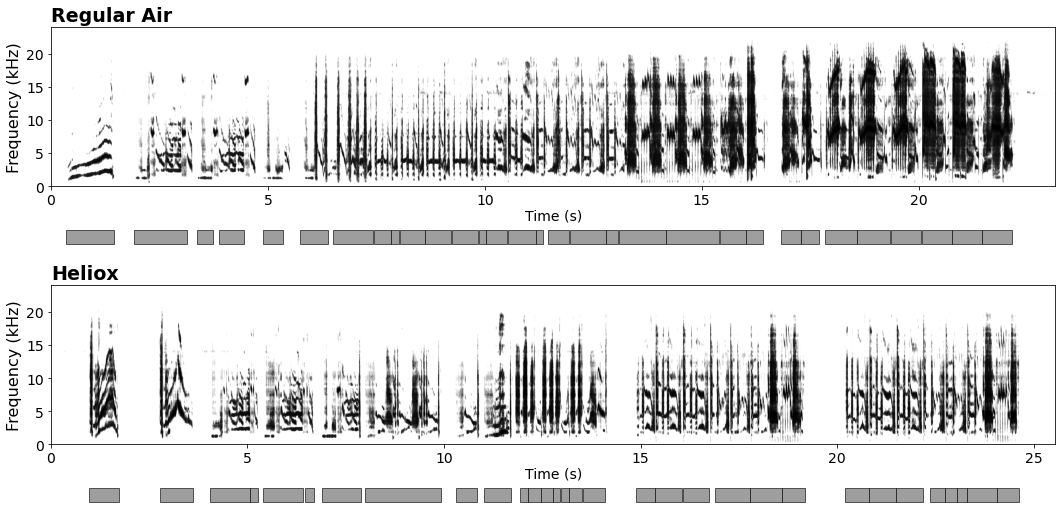

In [4]:
# Cell 4: Fig. 1C, starling song in regular air and in heliox
draw_songs('1C', 'fig1C_starling_songs', figsize=(18, 9.5))

saved /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/figures/fig1D_zebra_finch_songs.png


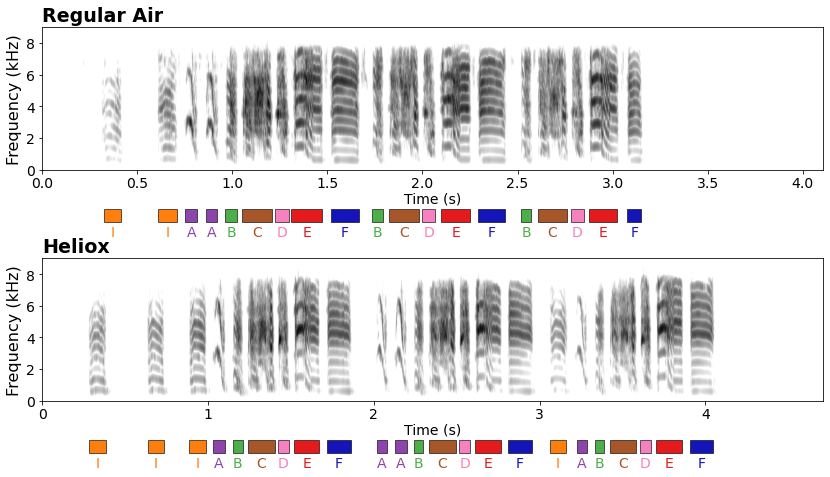

In [5]:
# Cell 5: Fig. 1D, zebra finch song in regular air and in heliox
draw_songs('1D', 'fig1D_zebra_finch_songs', figsize=(14, 8.5))

saved /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/figures/fig2B_zebra_finch_syllables.png


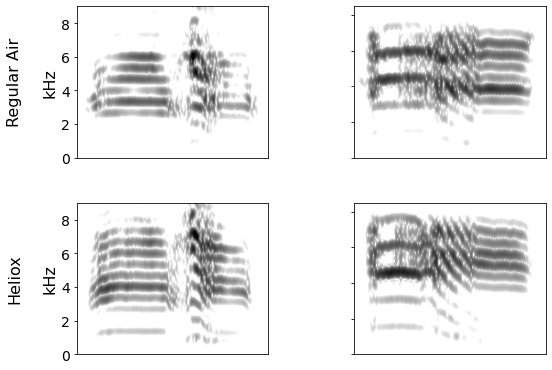

In [6]:
# Cell 6: Fig. 2B, zebra finch example syllables
draw_syllables('2B', 'fig2B_zebra_finch_syllables')

saved /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/figures/fig2D_starling_syllables.png


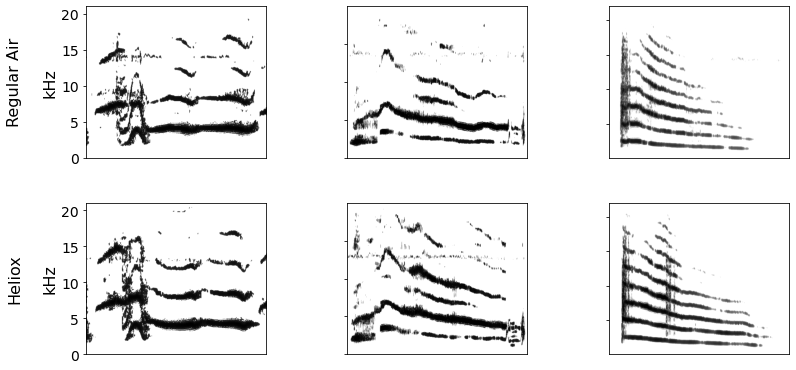

In [7]:
# Cell 7: Fig. 2D, starling example syllables
draw_syllables('2D', 'fig2D_starling_syllables')